<a href="https://colab.research.google.com/github/YoliyanaKeb/Data201-labs/blob/main/WEEK8HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATA 201 - Week 8 Homework

Finding the Right Amount of Regularization

Investigate how the strength of regularization affects model performance, complexity, and
interpretability

Load the ISLP Hitters dataset

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
hitters = load_data('Hitters')
hitters.head()


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


In [4]:
#remove the missing information
hitters = hitters.dropna(subset=['Salary']).copy()

#Set your features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary']    # thousands of dollars

#define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

#you can check how many rows went for each set
print(len(X), len(X_train), len(X_test))

['League', 'Division', 'NewLeague']
263 197 66


In [5]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])

baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
])

baseline.fit(X_train, y_train)

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


Part 1- Experiment with α

In [6]:
alpha_examples = [0.1,10, 100]
rows = []
for kind, estimator in [ ('Lasso', Lasso(max_iter=30000))]:

    for a in alpha_examples:
        pipe = Pipeline([
            ('preprocess', make_preprocessor()),
            ('model', estimator.set_params(alpha=a))
        ])
        pipe.fit(X_train, y_train)
        coefs = pipe.named_steps['model'].coef_
        rows.append({
            'Model': kind, 'alpha': a,
            'Training RMSE': np.sqrt(mean_squared_error(y_train, pipe.predict(X_train))),
            'Test RMSE': np.sqrt(mean_squared_error(y_test, pipe.predict(X_test))),
            'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)),
        })
alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,Model,alpha,Training RMSE,Test RMSE,Nonzero coefficients
0,Lasso,0.1,289.38,356.83,19
1,Lasso,10.0,303.10,381.84,9
2,Lasso,100.0,341.39,395.12,5


Questions:

1. As α increases, what happens to the number of retained predictors?

As alpha increases the number of predictors goes down. From my table I can see that at alpha = 0.1 there are 19 predictors but when alpha increases to 100 only 5 predictors are left.

2. Does a smaller number of predictors always lead to a lower test RMSE?

No, because when the number of predictors went down from 19 to 5 the test RMSE increased from 356.83 to 395.12. This means the model made more errors with fewer predictors because it might have removed some useful information.

Part 2 - Visualize and interpret

Create a graph showing α versus Test RMSE for the three models

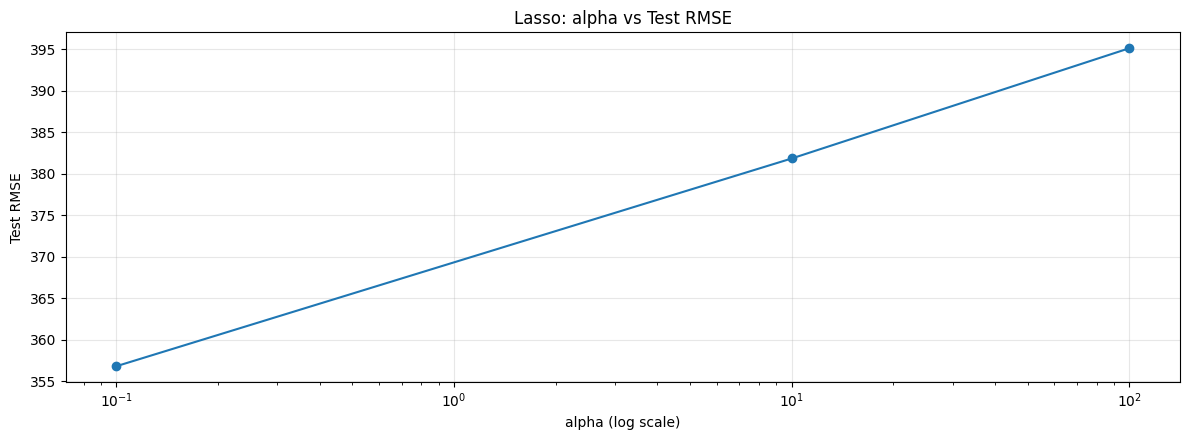

In [7]:
fig, axes = plt.subplots(figsize=(12, 4.5))
for ax, kind in zip([axes], [ 'Lasso']):
    subset = alpha_table[alpha_table['Model'] == kind]
    ax.semilogx(subset['alpha'], subset['Test RMSE'], marker='o')
    ax.set_title(f'{kind}: alpha vs Test RMSE')
    ax.set_xlabel('alpha (log scale)')
    ax.set_ylabel('Test RMSE')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

1. Which α produces the lowest test RMSE among the three values?

α =0.1 has the lowest test RMSE of 356.83.

2. Which α appears to cause the most underfitting? Explain using bias.

α 100 becuase it has the highest test RMSE and this shows that the model is way simple and and has bias.

3. Why might a model with higher training RMSE produce lower test RMSE?

The model with higher training RMSE might prodcuses lower test RMSE becuase the model is not trying to fit the traning data too much. This will help with the overfitting.

Part 3- Model interpretation

1. Identify two predictors that Lasso sets to zero at α = 100

In [8]:
feature_names =pipe.named_steps['preprocess'].get_feature_names_out()

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Lasso': pipe.named_steps['model'].coef_
})

display(coef_table.round(2))

,Feature,Lasso
0,num__AtBat,0.00
1,num__Hits,76.59
2,num__HmRun,0.00
3,num__Runs,0.00
4,num__RBI,0.00
5,num__Walks,16.17
6,num__Years,0.00
7,num__CAtBat,0.00
8,num__CHits,0.00
9,num__CHmRun,0.00


Based on this table the following is set to 0 by lasso.

2. Does setting their coefficients to zero prove that these predictors have no relationship
with salary? Explain.

No becuasse it might mean that they have no relationship with the salary and lasso might remove them becuase the other pridctions have similar info.

3. If two models have very similar test RMSE but one uses fewer predictors, which would
you prefer? Explain your answer in terms of interpretability and predictive performance.

I would choose the model with the fewer predictors becuase it is easier to understand.If both models have almost the same test RMSE then the model with fewer predictors can still make good predictions

Part 4 - Choosing the Right Regression Model

Scenario A:

 A researcher has data from 80 patients with 200 medical measurements. The
goal is to identify a small number of measurements that may be useful for predicting
disease severity

- Lasso

-becuase there are more predictors than the number of patients.Lasso can se some coefficients to 0 and remove the prdictor.

Scenario B:

A company wants to predict employee salaries using 40 predictors. Many
predictors are strongly correlated, and the company believes most contain useful
information. Keeping all predictors is not a concern

- Ridge

-becuase a lof of the predictors are related. It also makes the coefficent smaller which helps not to overfit.

Scenario C:

A researcher has 10,000 observations and only three predictors. The
relationship appears approximately linear, and the researcher wants a simple model that is
easy to interpret.

- Ordinary Linear Regression

-because there are many observations and only a few predictors. It can already be stable when there are many rows and only a few features.


Scenario D:

A company has 500 observations and 25 predictors. It is unclear how many
predictors are useful or how strongly they are correlated. The company wants the most
accurate predictions possible

- Not sure

-we dont know weather a few of the predicition or many of them are usefuel for this. I would use cross validation to compare which one works better.